# Opponency: do motif poles recruit opposite neuron groups?

Mouse 720762, deep prelimbic (PL5): 63 well-isolated units; spontaneous seconds (stimulus blocks ±5 s excluded),
each state separately.

**H1, opponent tracking.** For a motif, one group of neurons (A) fires more in its + pole and another group (B) in its
− pole, beyond a shared change in overall activity.
*Null:* all neurons shift the same way between poles (a gain change), or none shift.
*H1b:* A and B correspond to getClust ensembles.

**H2, baseline and populations.** As a motif's baseline moves:
- (a) the slow activity of A relative to B moves with it;
- (b) which neurons couple to the motif reorganises.

*Null:* coupling unchanged within noise, unrelated to the baseline.

**Order:** H1 for the original (strict) and relaxed motifs first, then the tracker, then H2 (tracker only; the binned
versions have no baseline over time).

**Method notes**
- Each neuron is z-scored within the state, then the population mean is regressed out ("global removed"); raw
  results are shown for contrast.
- Pole of a second = sign of the motif's expression.
- Neuron classification: a neuron is +preferring (−preferring) if its + minus − difference lies beyond the 97.5th
  (2.5th) percentile of its own null, built by circularly shifting the pole sequence by the same amount for all neurons.
  The same rule applied to each shift gives the null for the counts.
- Held-out test: A and B are defined on 4 of 5 interleaved 60-s block folds (top quarter by size, correct sign), then
  correlated with the motif on the fifth.
- H2 null: circular shifts of at least 300 s.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "..")
from src import motif_tracking as mt, spike_validation as sv
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
REPO = Path.cwd().resolve().parents[2]
NWB = REPO / "data" / "raw" / "720762-20240221-v001.nwb"
OUT = REPO / "data" / "out" / "2026-11-10_opponency"; OUT.mkdir(parents=True, exist_ok=True)
def save(fig, name): fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

res = mt.load(REPO / "data" / "processed" / "motif_tracking" / "720762" / "lfp_PL5.pkl")
sig = mt.prepare(NWB, "lfp_PL5", ("lfp", "probeF", "PL5"), res.config)
info, t = sig.info, sig.t
rate, unit_ids = sv.unit_rates(NWB, "PL5", t)
R = json.load(open(REPO / "data" / "out" / "2026-11-01_mouse720762" / "results.json"))
runs = {(r["window"], r["version"]): np.array(r["motifs"], float)[:, :r["n_motifs"]] for r in R["motif_runs"] if r["signal"] == "lfp_PL5"}
K = len(res.library)
E = res.second[[f"expr_M{i + 1}" for i in range(K)]].to_numpy()
Bm = res.second[[f"base_M{i + 1}" for i in range(K)]].to_numpy()
rng = np.random.default_rng(0)

S = {}
for st, m in sv.state_masks(t, info).items():
    m = m & np.isfinite(E).all(1) & np.isfinite(Bm).all(1)
    Zs = sig.Z[m]; Zs = (Zs - Zs.mean(0)) / Zs.std(0)
    motifs = {}
    for ver, label in (("strict", "Original"), ("relaxed", "Relaxed")):
        for win in (st, "full"):
            A = runs.get((win, ver))
            if A is not None and A.size:
                for j in range(A.shape[1]):
                    motifs[f"{label} · {win} motif"] = Zs @ (A[:, j] / np.linalg.norm(A[:, j]))
    for i in range(3):
        motifs[f"Tracker M{i + 1}"] = E[m][:, i]
    clusters, stab, X = sv.ensembles(rate, m)
    S[st] = dict(mask=m, motifs=motifs, Rg=sv.remove_global(rate[m]),
                 Rraw=(rate[m] - rate[m].mean(0)) / (rate[m].std(0) + 1e-12), clusters=clusters, X=X)
{st: list(d["motifs"]) for st, d in S.items()}

{'awake': ['Original · awake motif',
  'Relaxed · awake motif',
  'Relaxed · full motif',
  'Tracker M1',
  'Tracker M2',
  'Tracker M3'],
 'isoflurane': ['Relaxed · isoflurane motif',
  'Relaxed · full motif',
  'Tracker M1',
  'Tracker M2',
  'Tracker M3']}

## H1. Neurons split by pole, and the held-out test

In [2]:
rows, PC = [], {}
for st, d in S.items():
    for name, x in d["motifs"].items():
        raw = sv.pole_contrasts(x, d["Rraw"], rng, n_shift=500)
        g = sv.pole_contrasts(x, d["Rg"], rng, n_shift=500)
        ho = sv.heldout_opponency(x, d["Rg"], rng, n_shift=200)
        PC[st, name] = g
        rows.append({"state": st, "motif": name,
                     "raw: + / − neurons": f"{raw['n_plus']} / {raw['n_minus']}",
                     "global removed: + / − neurons": f"{g['n_plus']} / {g['n_minus']}",
                     "chance (95th pct)": f"{g['null_plus_95']:.0f} / {g['null_minus_95']:.0f}",
                     "p (both signs)": g["p_both"],
                     "held-out r(A)": ho["r_A"], "p(A)": ho["p_A"], "held-out r(B)": ho["r_B"], "p(B)": ho["p_B"],
                     "held-out r(A−B)": ho["r_AminusB"], "p(A−B)": ho["p_AminusB"], "null95 r(A−B)": ho["null95_AminusB"]})
h1 = pd.DataFrame(rows); h1.to_csv(OUT / "h1_opponency.csv", index=False)
h1.round(3)

,state,motif,raw: + / − neurons,global removed: + / − neurons,chance (95th pct),p (both signs),held-out r(A),p(A),held-out r(B),p(B),held-out r(A−B),p(A−B),null95 r(A−B)
0,awake,Original · awake motif,20 / 5,8 / 8,4 / 5,0.002,0.199,0.264,-0.351,0.015,0.316,0.025,0.296
1,awake,Relaxed · awake motif,20 / 6,7 / 9,4 / 5,0.002,0.241,0.209,-0.370,0.015,0.350,0.035,0.325
2,awake,Relaxed · full motif,4 / 4,4 / 3,4 / 5,0.102,0.267,0.005,-0.171,0.134,0.251,0.010,0.192
3,awake,Tracker M1,9 / 5,10 / 10,4 / 4,0.002,0.155,0.109,-0.194,0.040,0.185,0.055,0.182
4,awake,Tracker M2,2 / 4,1 / 4,4 / 4,0.649,-0.014,0.294,-0.053,0.139,0.020,0.144,0.072
5,awake,Tracker M3,5 / 0,4 / 1,4 / 4,0.563,0.125,0.100,0.056,0.622,0.047,0.249,0.157
6,isoflurane,Relaxed · isoflurane motif,42 / 0,4 / 6,5 / 5,0.060,0.220,0.826,-0.370,0.254,0.337,0.557,0.453
7,isoflurane,Relaxed · full motif,23 / 2,9 / 7,5 / 5,0.012,0.286,0.149,-0.465,0.005,0.427,0.025,0.362
8,isoflurane,Tracker M1,62 / 0,8 / 8,5 / 5,0.008,0.256,0.005,-0.118,0.025,0.214,0.005,0.092
9,isoflurane,Tracker M2,33 / 1,8 / 11,4 / 5,0.004,0.358,0.005,-0.433,0.005,0.451,0.005,0.127


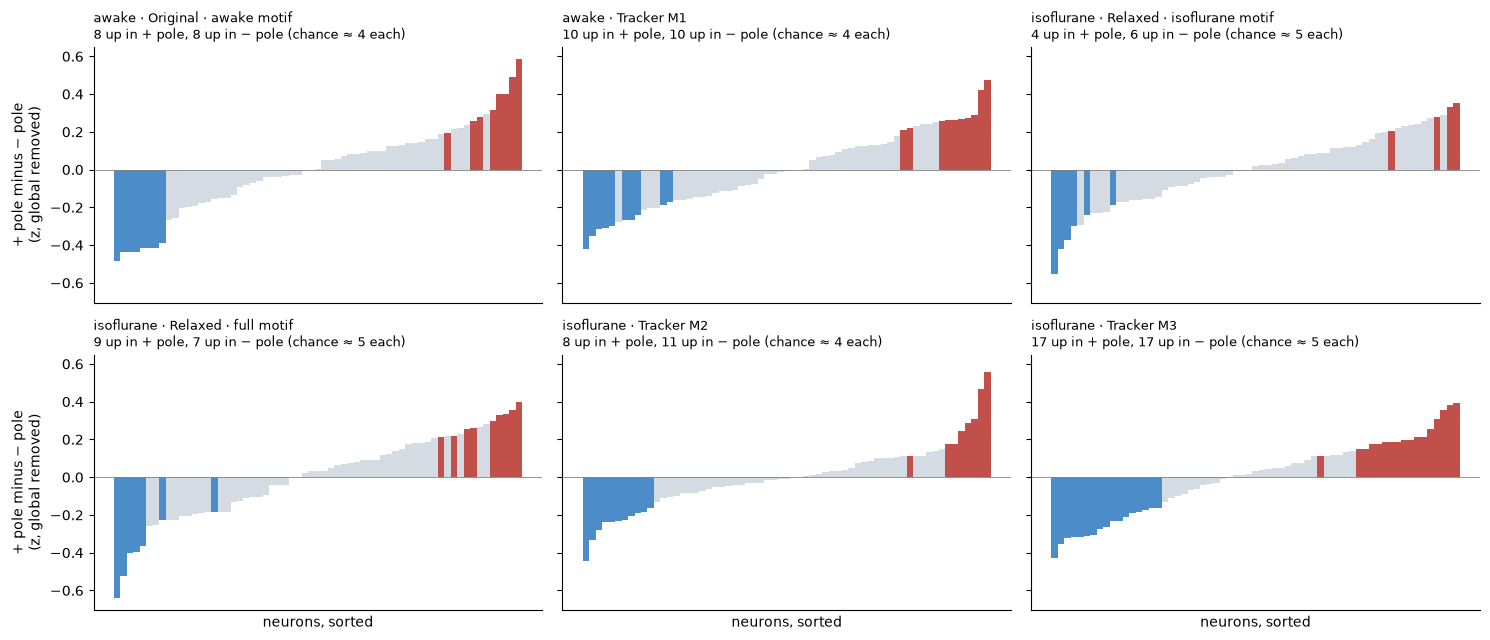

In [3]:
show = [("awake", "Original · awake motif"), ("awake", "Tracker M1"), ("isoflurane", "Relaxed · isoflurane motif"),
        ("isoflurane", "Relaxed · full motif"), ("isoflurane", "Tracker M2"), ("isoflurane", "Tracker M3")]
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharey=True)
for ax, key in zip(axes.flat, show):
    g = PC[key]; o = np.argsort(g["d"])
    col = np.where(g["plus"][o], "#C2504A", np.where(g["minus"][o], "#4C8DC9", "#D5DBE2"))
    ax.bar(range(len(o)), g["d"][o], color=col, width=1.0)
    ax.axhline(0, color="0.5", lw=0.6)
    ax.set_title(f"{key[0]} · {key[1]}\n{g['n_plus']} up in + pole, {g['n_minus']} up in − pole (chance ≈ {g['null_plus_95']:.0f} each)", fontsize=9, loc="left")
    ax.set_xticks([]); ax.spines[["top", "right"]].set_visible(False)
for ax in axes[:, 0]: ax.set_ylabel("+ pole minus − pole\n(z, global removed)")
for ax in axes[1]: ax.set_xlabel("neurons, sorted")
fig.tight_layout(); save(fig, "h1_neuron_split"); plt.show()

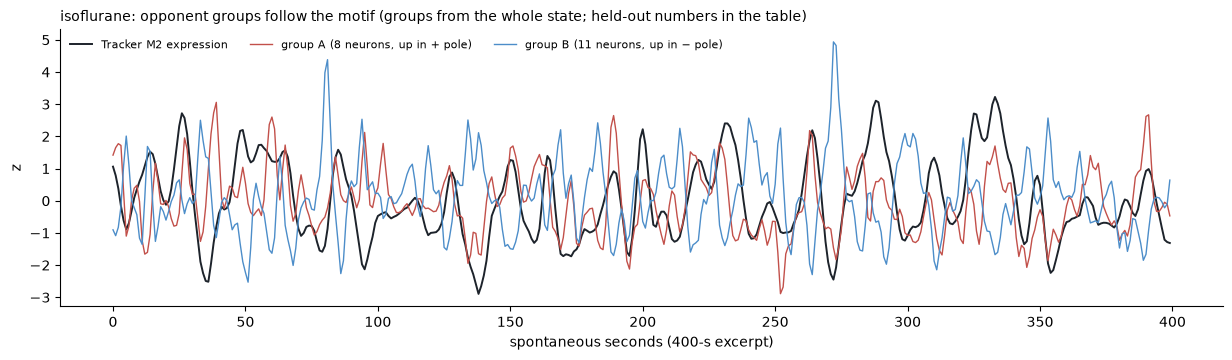

In [4]:
st, name = "isoflurane", "Tracker M2"
d = S[st]; x = d["motifs"][name]
pc = PC[st, name]
A, B = d["Rg"][:, pc["plus"]].mean(1), d["Rg"][:, pc["minus"]].mean(1)
seg = slice(300, 700)
fig, ax = plt.subplots(figsize=(15, 3.6))
ax.plot(sv.zscore(x)[seg], color="#1D232B", lw=1.4, label=f"{name} expression")
ax.plot(sv.zscore(A)[seg], color="#C2504A", lw=1, label=f"group A ({pc['n_plus']} neurons, up in + pole)")
ax.plot(sv.zscore(B)[seg], color="#4C8DC9", lw=1, label=f"group B ({pc['n_minus']} neurons, up in − pole)")
ax.legend(fontsize=8, frameon=False, ncol=3, loc="upper left"); ax.set_xlabel("spontaneous seconds (400-s excerpt)")
ax.set_ylabel("z"); ax.set_title(f"{st}: opponent groups follow the motif (groups from the whole state; held-out numbers in the table)", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
save(fig, "h1_traces"); plt.show()

### H1b. Do the opponent groups line up with getClust ensembles?

In [5]:
erows = []
for (st, name), g in PC.items():
    for e, c in enumerate(S[st]["clusters"]):
        erows.append({"state": st, "motif": name, "ensemble": f"E{e + 1} ({len(c)} units)",
                      "share in A (+)": g["plus"][c].mean(), "share in B (−)": g["minus"][c].mean()})
ens = pd.DataFrame(erows)
alt = {st: sv.ensemble_alternation(d["X"], d["clusters"]).round(2) for st, d in S.items()}
print("correlation between ensembles' activity:", alt)
ens.pivot_table(index=["state", "motif"], columns="ensemble", values=["share in A (+)", "share in B (−)"]).round(2)

correlation between ensembles' activity: {'awake': array([[ 1.  , -0.11],
       [-0.11,  1.  ]]), 'isoflurane': array([[1.  , 0.08, 0.07],
       [0.08, 1.  , 0.29],
       [0.07, 0.29, 1.  ]])}


share in A (+)                \
ensemble                               E1 (27 units) E1 (32 units)   
state      motif                                                     
awake      Original · awake motif                NaN          0.12   
           Relaxed · awake motif                 NaN          0.12   
           Relaxed · full motif                  NaN          0.06   
           Tracker M1                            NaN          0.19   
           Tracker M2                            NaN          0.03   
           Tracker M3                            NaN          0.03   
isoflurane Relaxed · full motif                 0.33           NaN   
           Relaxed · isoflurane motif           0.15           NaN   
           Tracker M1                           0.04           NaN   
           Tracker M2                           0.07           NaN   
           Tracker M3                           0.04           NaN   

                                                                               \
ensemble                              E2 (25 units) E2 (6 units) E3 (6 units)   
state      motif                                                                
awake      Original · awake motif               NaN         0.00          NaN   
           Relaxed · awake motif                NaN         0.00          NaN   
           Relaxed · full motif                 NaN         0.17          NaN   
           Tracker M1                           NaN         0.17          NaN   
           Tracker M2                           NaN         0.00          NaN   
           Tracker M3                           NaN         0.00          NaN   
isoflurane Relaxed · full motif                0.00          NaN         0.00   
           Relaxed · isoflurane motif          0.00          NaN         0.00   
           Tracker M1                          0.20          NaN         0.17   
           Tracker M2                          0.24          NaN         0.00   
           Tracker M3                          0.52          NaN         0.33   

                                      share in B (−)                \
ensemble                               E1 (27 units) E1 (32 units)   
state      motif                                                     
awake      Original · awake motif                NaN          0.03   
           Relaxed · awake motif                 NaN          0.06   
           Relaxed · full motif                  NaN          0.06   
           Tracker M1                            NaN          0.25   
           Tracker M2                            NaN          0.09   
           Tracker M3                            NaN          0.03   
isoflurane Relaxed · full motif                 0.00           NaN   
           Relaxed · isoflurane motif           0.00           NaN   
           Tracker M1                           0.15           NaN   
           Tracker M2                           0.30           NaN   
           Tracker M3                           0.59           NaN   

                                                                               
ensemble                              E2 (25 units) E2 (6 units) E3 (6 units)  
state      motif                                                               
awake      Original · awake motif               NaN          0.0          NaN  
           Relaxed · awake motif                NaN          0.0          NaN  
           Relaxed · full motif                 NaN          0.0          NaN  
           Tracker M1                           NaN          0.0          NaN  
           Tracker M2                           NaN          0.0          NaN  
           Tracker M3                           NaN          0.0          NaN  
isoflurane Relaxed · full motif                0.20          NaN         0.00  
           Relaxed · isoflurane motif          0.20          NaN         0.00  
           Tracker M1                          0.08          

## H2. Baseline shifts and the neuron populations (tracker)

In [6]:
rows = []
for st, d in S.items():
    tt = t[d["mask"]]
    for i in range(3):
        x, b = E[d["mask"]][:, i], Bm[d["mask"]][:, i]
        a_ = sv.slow_opponency(x, b, d["Rg"], tt, rng)
        b_ = sv.membership_shift(x, b, d["Rg"], tt, rng)
        rows.append({"state": st, "motif": f"Tracker M{i + 1}", "baseline range": np.ptp(b),
                     "(a) r(baseline, slow A−B)": a_["r"], "(a) p": a_["p"], "(a) null95 |r|": a_.get("null95", np.nan),
                     "(b) within": b_["within"], "(b) low vs high": b_["between"], "(b) reorganisation": b_["reorganisation"],
                     "(b) p": b_["p"], "(b) null95": b_["null95"]})
h2 = pd.DataFrame(rows); h2.to_csv(OUT / "h2_baseline.csv", index=False)
h2.round(3)

,state,motif,baseline range,"(a) r(baseline, slow A−B)",(a) p,(a) null95 |r|,(b) within,(b) low vs high,(b) reorganisation,(b) p,(b) null95
0,awake,Tracker M1,0.853,0.289,0.104,0.303,0.333,0.254,0.079,0.363,0.355
1,awake,Tracker M2,0.372,0.111,0.501,0.261,0.175,0.086,0.088,0.229,0.178
2,awake,Tracker M3,0.697,0.468,0.114,0.476,0.133,0.182,-0.049,0.547,0.177
3,isoflurane,Tracker M1,10.271,-0.039,0.709,0.362,0.543,0.342,0.201,0.866,0.585
4,isoflurane,Tracker M2,4.842,0.309,0.002,0.277,0.631,0.654,-0.024,0.846,0.177
5,isoflurane,Tracker M3,4.359,0.272,0.469,0.610,0.656,0.237,0.419,0.005,0.302


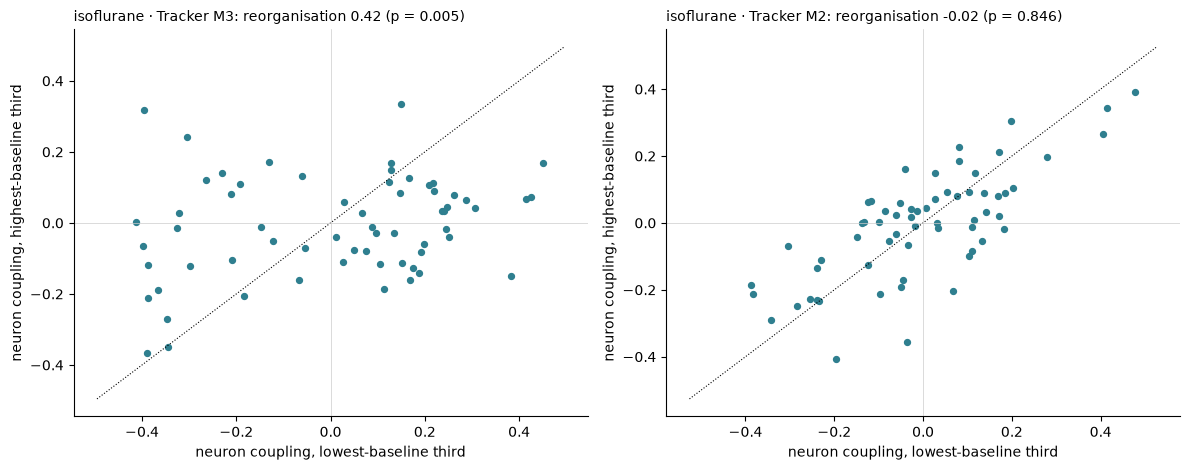

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (st, i) in zip(axes, [("isoflurane", 2), ("isoflurane", 1)]):
    d = S[st]; tt = t[d["mask"]]
    x, b = sv.detrend(E[d["mask"]][:, i], tt), Bm[d["mask"]][:, i]
    Rf = sv.detrend(d["Rg"], tt)
    lo, hi = np.quantile(b, [1 / 3, 2 / 3])
    cl, ch = sv._corr_cols(Rf[b <= lo], x[b <= lo]), sv._corr_cols(Rf[b >= hi], x[b >= hi])
    ax.scatter(cl, ch, s=18, color="#2F7F8F")
    lim = max(np.abs(cl).max(), np.abs(ch).max()) * 1.1
    ax.plot([-lim, lim], [-lim, lim], "k:", lw=0.8); ax.axhline(0, color="0.8", lw=0.5); ax.axvline(0, color="0.8", lw=0.5)
    r = h2[(h2.state == st) & (h2.motif == f"Tracker M{i + 1}")].iloc[0]
    ax.set_title(f"{st} · Tracker M{i + 1}: reorganisation {r['(b) reorganisation']:.2f} (p = {r['(b) p']:.3f})", fontsize=10, loc="left")
    ax.set_xlabel("neuron coupling, lowest-baseline third"); ax.set_ylabel("neuron coupling, highest-baseline third")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); save(fig, "h2_membership"); plt.show()

## Conclusions

**H1, opponent groups: supported once the shared change in activity is removed.**
- Raw, every motif mainly moves all neurons the same way (e.g. 42 up / 0 down for the relaxed isoflurane motif, 62 / 0
  for tracker M1 under isoflurane). That is a gain change, not opponency.
- With the population mean regressed out, most motifs have significant neurons of both signs (about 4–5 expected by
  chance): the original/relaxed awake motif 8/8 and 7/9; tracker M1 awake 10/10; tracker M2 and M3 under isoflurane
  8/11 and 17/17.
- Held-out (groups chosen on other blocks): the binned awake motif's A − B follows it at r ≈ 0.32–0.35 (p 0.03),
  mostly through the B group. Under isoflurane the relaxed full-recording motif gives r = 0.43 (p 0.03) and the relaxed
  isoflurane motif nothing beyond chance. Tracker M2 and M3 under isoflurane give r = 0.45 and 0.35 with both A and B
  significant on their own (p 0.005).
- So the original and relaxed motifs do show opponency, awake mainly. The tracker shows it more clearly under
  isoflurane. Part of the tracker's sharper p-values comes from its signals being faster, which makes the time-shift
  null narrower.

**H1b, getClust ensembles: partly.** The ensembles themselves don't alternate (activity correlations −0.11 to 0.29,
global activity included). Under isoflurane, tracker M3's groups split the two large ensembles: 59% of E1 is in its
− group and 52% of E2 in its + group. Tracker M2 and the relaxed full motif show the same split, more weakly.

**H2a, slow A − B following the baseline: weak.** Only tracker M2 under isoflurane passes (r = 0.31, p = 0.002). The
awake cases that passed in a first run did not survive new random draws (p ≈ 0.1). Spontaneous isoflurane time has
little dose change (the high-dose period is inside the stimulation block, which is excluded), so the baseline range
tested here is narrow.

**H2b, membership reorganising with the baseline: one clear case.** Tracker M3 under isoflurane: the neurons coupled
to it in its lowest-baseline third differ from those in its highest third (half-to-half agreement 0.66 within thirds
vs 0.24 between, p = 0.005). M2 keeps the same neurons (−0.02); M1 and the awake motifs show nothing beyond the null.

**Caveats.** 63 units in one region; one session; motifs detected on the same data; 11 motif × state rows and two H2
tests per motif, so isolated p ≈ 0.03 results should be treated as tentative.